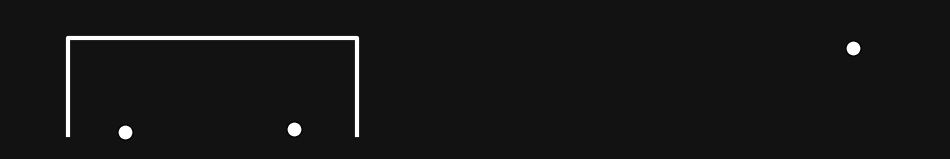

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

data = {
    "start_x": [ 27.8, 8.2],
    "start_y": [46.4,  72.4],
    "goal_mouth_y": [ 47.3,  52.9],
    "goal_mouth_z": [ 5.7,  2.5],
}
df = pd.DataFrame(data)

# Opta Pitch Y post coordinates (54.8 = Left Post, 45.2 = Right Post)
POST_LEFT = 54.8
POST_RIGHT = 45.2

# Invert Y mapping for shooter perspective (0 = Left Post, 100 = Right Post)
df["goal_y_relative"] = (
    (POST_LEFT - df["goal_mouth_y"]) / (POST_LEFT - POST_RIGHT)
) * 100

# Scale Z height to physical 3:1 goal proportions (100 wide by 33.33 high)
CROSSBAR_HEIGHT = 100.0 / 3.0
df["goal_z_relative"] = (df["goal_mouth_z"] / 100.0) * CROSSBAR_HEIGHT

fig, ax = plt.subplots(figsize=(12, 4))

# Draw Goal Frame
ax.plot([0, 0, 100, 100], [0, CROSSBAR_HEIGHT, CROSSBAR_HEIGHT, 0], color="white", lw=3)

# Scatter Shots
ax.scatter(
    df["goal_y_relative"],
    df["goal_z_relative"],
    color="white",
    edgecolors="black",
    s=120,
    zorder=3,
)

# Dynamically set limits to fit the extreme outliers + goal frame
x_min = min(-20, df["goal_y_relative"].min() - 30)
x_max = max(120, df["goal_y_relative"].max() + 30)
ax.set_xlim(x_min, x_max)
ax.set_ylim(-5, CROSSBAR_HEIGHT + 10)

# Preserve 1:1 data geometry so the goal never distorts into a tall rectangle
ax.set_aspect("equal", adjustable="box")

# Dark Mode Styling
fig.patch.set_facecolor("#121212")
ax.set_facecolor("#121212")
ax.axis("off")

plt.show()